# Cross-Service Mobility Comparison

**SI 671 supplementary analysis:** June 2025 Yellow Taxi vs Uber vs Lyft. This notebook only displays output of `src/supplementary/cross_service_comparison.py` and can optionally run it. See `README_CROSS_SERVICE.md` for definitions and limitations.

In [7]:
from pathlib import Path
import subprocess, sys
from IPython.display import display, Image
import pandas as pd
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "results/cross_service"
print("Project root:", ROOT)

Project root: /Users/eunicegu/si671-final/Urban-Mobility-Mining


## 1. Recompute aggregated outputs only if needed

With the large HVFHV Parquet already downloaded, the script uses DuckDB on disk to aggregate trips. It should not be run twice unnecessarily. Set `RECOMPUTE = True` to force regeneration.

In [8]:
RECOMPUTE = False
if RECOMPUTE or not (OUT / "summary.csv").exists():
    subprocess.run([sys.executable, "-m", "src.supplementary.cross_service_comparison"], cwd=ROOT, check=True)
else:
    print("Using existing outputs in", OUT)

Using existing outputs in /Users/eunicegu/si671-final/Urban-Mobility-Mining/results/cross_service


## 2. Data quality audit

`n_month_rows` counts selected-service pickup records with timestamps in June. `n_eligible_pickups` further requires the zone to belong to the TLC lookup and not be IDs 264/265.

In [9]:
qa = pd.read_csv(OUT / "quality_checks.csv")
display(qa)
assert (qa.n_month_rows >= qa.n_eligible_pickups).all()

,service,n_month_rows,n_eligible_pickups,n_excluded_unknown_or_special_zone
0,Yellow,4322940,4314345,8595
1,Lyft,5700648,5700387,261
2,Uber,14167361,14166709,652


## 3. Overview statistics

In [10]:
summary = pd.read_csv(OUT / "summary.csv")
display(summary)

,service,eligible_pickups_june,active_zones,manhattan_share,ewr_share,top10_zone_share,weekend_share_typical_week,zone_share_spearman_vs_yellow
0,Yellow,4314345,257,0.846042,0.000113,0.333471,0.280284,1.000000
1,Uber,14166709,259,0.354740,0.000000,0.131866,0.300387,0.831284
2,Lyft,5700387,260,0.367883,0.000000,0.133885,0.310501,0.873722


## 4. Spatial footprint

Fractions are computed *within each service*, not market shares. EWR is a separate out-of-city category.

service,Lyft,Uber,Yellow
Borough,,,
Bronx,0.115543,0.132915,0.008300
Brooklyn,0.284815,0.268912,0.043674
EWR,0.000000,0.000000,0.000113
Manhattan,0.367883,0.354740,0.846042
Queens,0.219177,0.226152,0.101761
Staten Island,0.012582,0.017281,0.000111


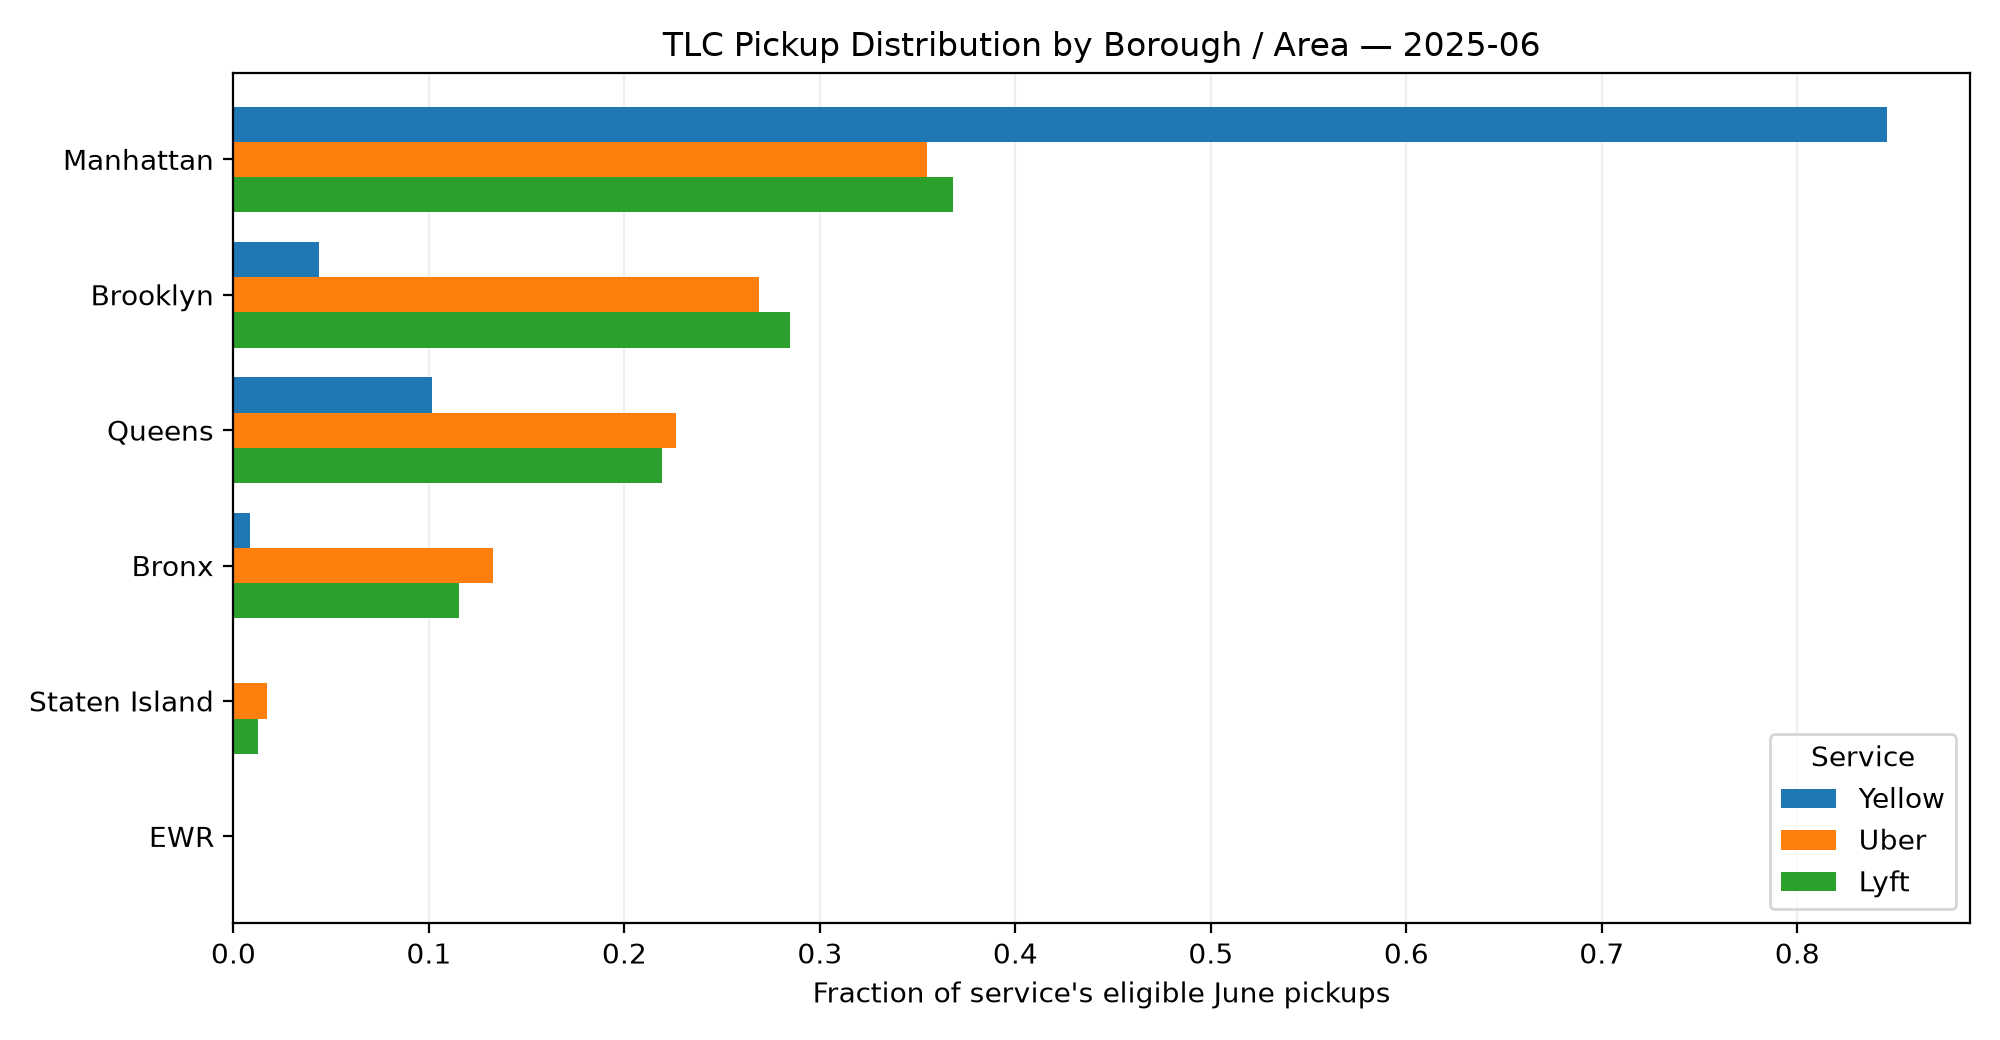

In [11]:
display(pd.read_csv(OUT / "borough_share.csv").pivot(index="Borough", columns="service", values="pickup_share"))
display(Image(filename=str(OUT / "figures/borough_pickup_share.png")))

## 5. Temporal demand profiles

The 168D profiles are averaged per calendar weekday occurrence, then normalized separately for each service. Common color scale across all panels.

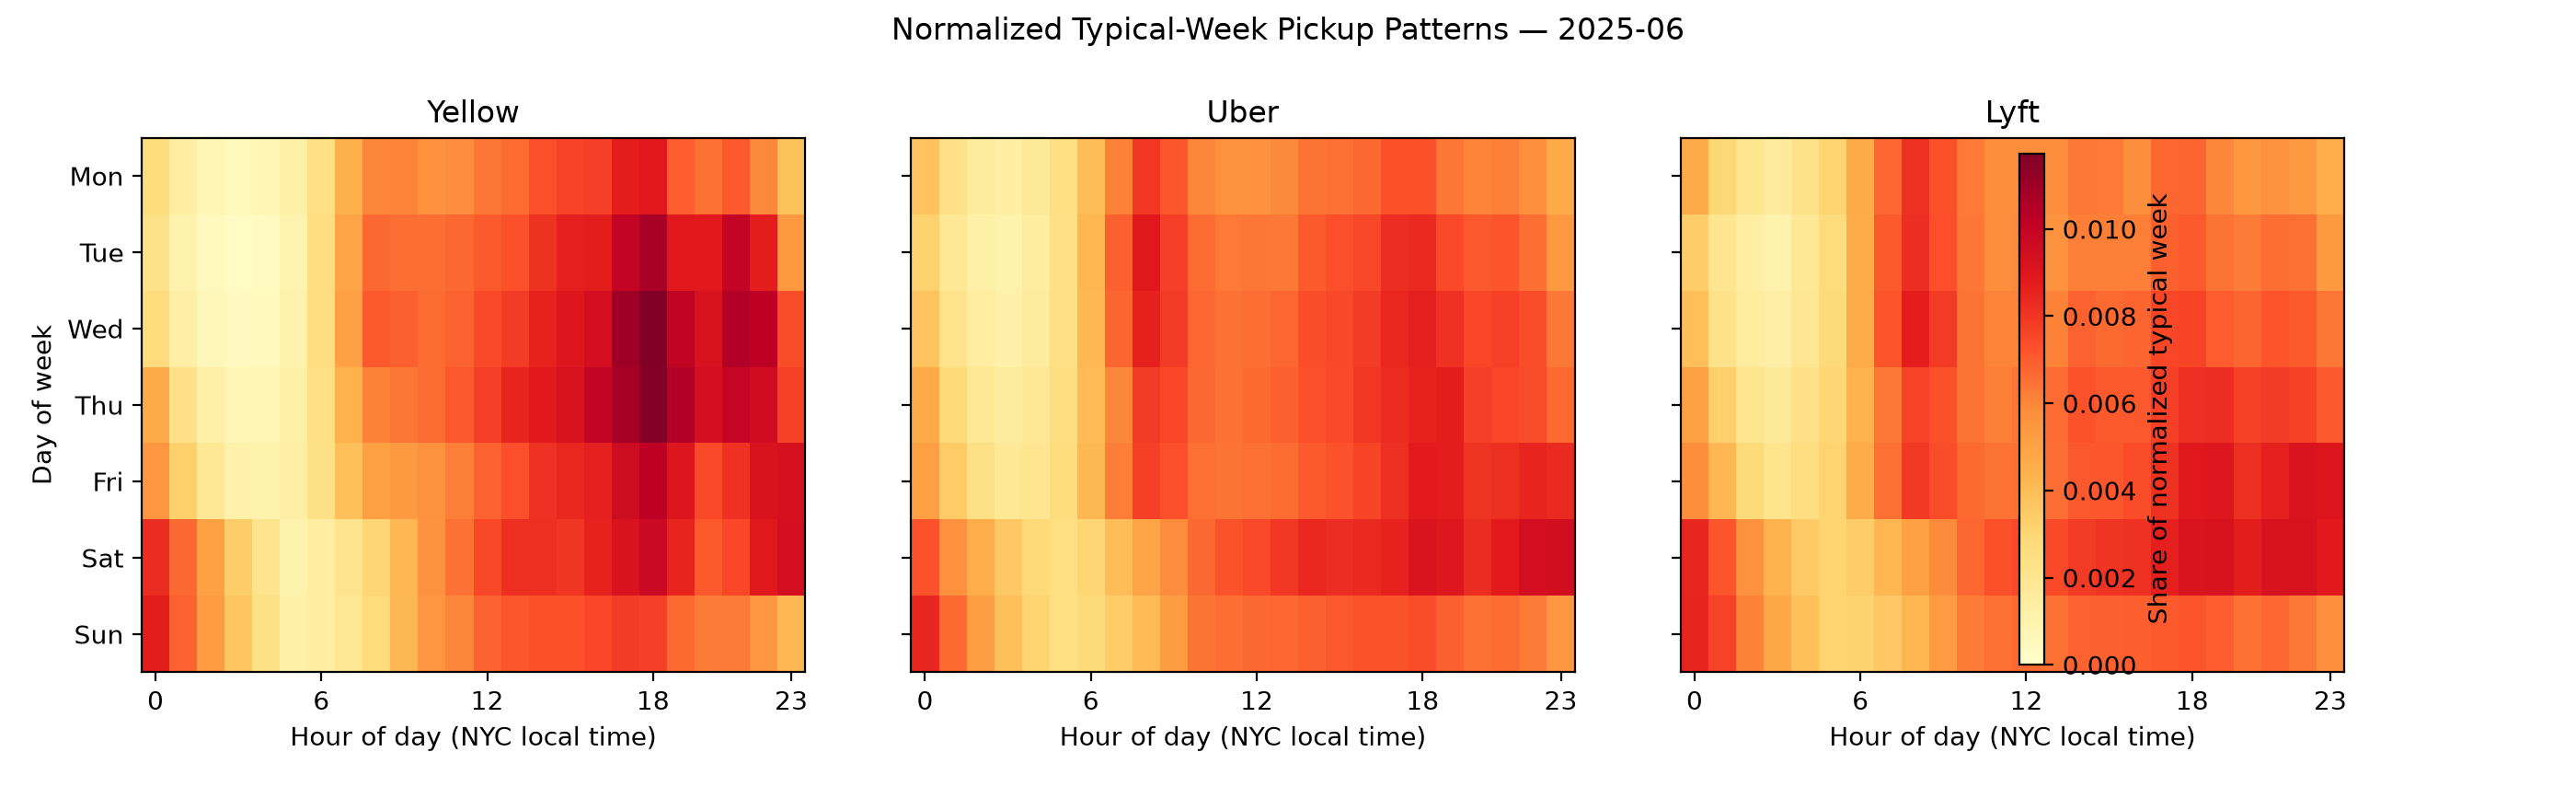

In [12]:
display(Image(filename=str(OUT / "figures/weekday_hour_heatmaps.png")))

## 6. Interpretation prompts

- How do service-specific pickup shares differ across Manhattan and outer boroughs?
- Which services have higher top-10 pickup-zone concentration?
- How similar are their weekday-hour shapes?
- Is the yellow-only OD interpretation portable to other services?

**Limitations:** one-month descriptive comparison, distinct source cleaning rules, EWR zone, and no causal conclusions about substitution, congestion pricing, or forecast effects.